In [3]:

from pathlib import Path
from collections import Counter
import pandas as pd

from canids.io import (
    files_for_split,
    csv_has_header,
    COLUMNS
)

root = Path("../data/raw/can-train-and-test/set_01").resolve()

train_files = files_for_split(root, "train_01")

print(f"Found {len(train_files)} training files")

target_payloads = [
    "0000000000000000",
    "2026662920DA1D72"
]

# Accumulate statistics without keeping all frames
capture_stats = []
id_counts = Counter()
payload_counts = Counter()
c1_attack_patterns = Counter()

for path in train_files:
    source = path.relative_to(root).as_posix()

    normal_count = 0
    attack_count = 0

    reader = pd.read_csv(
        path,
        header=None,
        names=COLUMNS,
        skiprows=1 if csv_has_header(path) else 0,
        usecols=["arbitration_id", "data_field", "attack"],
        dtype="string",
        chunksize=200_000
    )

    for chunk in reader:
        labels = chunk["attack"].str.strip()

        if not labels.isin(["0", "1"]).all():
            raise ValueError(f"Invalid attack labels in {source}")

        # Normalize hexadecimal CAN IDs
        ids = (
            chunk["arbitration_id"]
            .str.strip()
            .str.upper()
            .str.replace(r"^0X", "", regex=True)
            .str.lstrip("0")
            .replace("", "0")
        )

        payloads = (
            chunk["data_field"]
            .str.upper()
            .str.replace(" ", "", regex=False)
        )

        normal_count += int(labels.eq("0").sum())
        attack_count += int(labels.eq("1").sum())

        # Count normal and attack frames by CAN ID
        counts = pd.DataFrame({
            "can_id": ids,
            "label": labels
        }).value_counts()

        for (can_id, label), count in counts.items():
            id_counts[(can_id, label)] += int(count)

        # Look for our two specific DoS payloads
        is_c1 = ids.eq("C1")

        for target in target_payloads:
            matches = is_c1 & payloads.eq(target)

            for label in ["0", "1"]:
                n = int((matches & labels.eq(label)).sum())
                payload_counts[(target, label)] += n

        # Count all injected payload patterns for ID 0x0C1
        c1_attacks = payloads[
            is_c1 & labels.eq("1")
        ].value_counts()

        for payload, count in c1_attacks.items():
            c1_attack_patterns[(source, payload)] += int(count)

    capture_stats.append({
        "source_file": source,
        "normal_frames": normal_count,
        "attack_frames": attack_count,
        "total_frames": normal_count + attack_count
    })

    print(f"Completed: {source}")

capture_df = pd.DataFrame(capture_stats)
capture_df["attack_rate"] = (
    capture_df["attack_frames"] /
    capture_df["total_frames"]
)

print("\nFULL TRAINING DATASET SUMMARY")
print("Total frames:", capture_df["total_frames"].sum())
print("Normal frames:", capture_df["normal_frames"].sum())
print("Attack frames:", capture_df["attack_frames"].sum())

display(capture_df)


Found 12 training files
Completed: train_01/accessory-1.csv
Completed: train_01/accessory-2.csv
Completed: train_01/attack-free-1.csv
Completed: train_01/attack-free-2.csv
Completed: train_01/DoS-1.csv
Completed: train_01/DoS-2.csv
Completed: train_01/force-neutral-1.csv
Completed: train_01/force-neutral-2.csv
Completed: train_01/rpm-1.csv
Completed: train_01/rpm-2.csv
Completed: train_01/standstill-1.csv
Completed: train_01/standstill-2.csv

FULL TRAINING DATASET SUMMARY
Total frames: 10653140
Normal frames: 10603583
Attack frames: 49557


,source_file,normal_frames,attack_frames,total_frames,attack_rate
0,train_01/accessory-1.csv,207704,0,207704,0.000000
1,train_01/accessory-2.csv,226166,0,226166,0.000000
2,train_01/attack-free-1.csv,1952833,0,1952833,0.000000
3,train_01/attack-free-2.csv,1265599,0,1265599,0.000000
4,train_01/DoS-1.csv,81030,9139,90169,0.101354
5,train_01/DoS-2.csv,285091,25954,311045,0.083441
6,train_01/force-neutral-1.csv,708935,6500,715435,0.009085
7,train_01/force-neutral-2.csv,997993,492,998485,0.000493
8,train_01/rpm-1.csv,837715,3338,841053,0.003969
9,train_01/rpm-2.csv,822085,374,822459,0.000455


In [4]:

# Full training dataset: CAN IDs and labels

id_rows = []

for can_id in {key[0] for key in id_counts}:
    normal = id_counts[(can_id, "0")]
    attacks = id_counts[(can_id, "1")]

    id_rows.append({
        "can_id": f"0x{int(can_id, 16):03X}",
        "normal_frames": normal,
        "attack_frames": attacks,
        "attack_rate": (
            attacks / (normal + attacks)
            if normal + attacks else 0
        )
    })

id_df = pd.DataFrame(id_rows)

print("CAN IDs associated with injected frames:")

display(
    id_df[id_df["attack_frames"] > 0]
    .sort_values("attack_frames", ascending=False)
)

# Check both target payloads across the full training set
print("\nTarget payload comparison:")

payload_summary = pd.DataFrame([
    {
        "payload": p,
        "normal_frames": payload_counts[(p, "0")],
        "attack_frames": payload_counts[(p, "1")]
    }
    for p in target_payloads
])

display(payload_summary)

# Inspect all observed injected 0x0C1 payload patterns
print("\nInjected CAN ID 0x0C1 payloads by capture:")

patterns_df = pd.DataFrame([
    {
        "source_file": source,
        "payload": payload,
        "attack_frames": count
    }
    for (source, payload), count
    in c1_attack_patterns.items()
])

display(
    patterns_df.sort_values(
        "attack_frames", ascending=False
    ).head(30)
)


CAN IDs associated with injected frames:


,can_id,normal_frames,attack_frames,attack_rate
35,0x0C1,815110,25954,0.030859
49,0x000,0,9139,1.000000
2,0x0C9,586777,7472,0.012574
33,0x1F5,293275,6992,0.023286



Target payload comparison:


,payload,normal_frames,attack_frames
0,0000000000000000,4772,25954
1,2026662920DA1D72,1,0



Injected CAN ID 0x0C1 payloads by capture:


,source_file,payload,attack_frames
0,train_01/DoS-2.csv,0000000000000000,25954


In [6]:

from pathlib import Path
import pandas as pd

from canids.io import (
    files_for_split,
    csv_has_header,
    COLUMNS
)

root = Path("../data/raw/can-train-and-test/set_01").resolve()

target_payload = "2026662920DA1D72"
matches = []

for path in files_for_split(root, "train_01"):

    reader = pd.read_csv(
        path,
        header=None,
        names=COLUMNS,
        skiprows=1 if csv_has_header(path) else 0,
        dtype="string",
        chunksize=200_000
    )

    for chunk in reader:
        ids = (
            chunk["arbitration_id"]
            .str.strip().str.upper()
            .str.replace(r"^0X", "", regex=True)
            .str.lstrip("0")
            .replace("", "0")
        )

        payloads = (
            chunk["data_field"]
            .str.strip().str.upper()
            .str.replace(" ", "", regex=False)
        )

        mask = (
            ids.eq("C1") &
            payloads.eq(target_payload)
        )

        if mask.any():
            found = chunk.loc[mask].copy()
            found["source_file"] = path.name
            matches.append(found)

if matches:
    result = pd.concat(matches, ignore_index=True)
    display(result)
else:
    print("No matches found.")


,timestamp,arbitration_id,data_field,attack,source_file
0,1672531202.076127,0C1,2026662920DA1D72,0,DoS-1.csv


### Feature ablation analysis

In [9]:

import pandas as pd

from canids.io import load_sample
from canids.features import frame_features

root = "../data/raw/can-train-and-test/set_01"

# Reproduce our original 2% training sample
df = load_sample(
    root,
    "train_01",
    fraction=0.02,
    seed=42
)

# Extract all ten frame-level features
X = frame_features(df)
y = df["attack"]

print("Total frames:", len(df))
print("Feature columns:", X.columns.tolist())
print("\nClass distribution:")
print(y.value_counts())


  reading train_01\accessory-1.csv
  reading train_01\accessory-2.csv
  reading train_01\attack-free-1.csv
  reading train_01\attack-free-2.csv
  reading train_01\DoS-1.csv
  reading train_01\DoS-2.csv
  reading train_01\force-neutral-1.csv
  reading train_01\force-neutral-2.csv
  reading train_01\rpm-1.csv
  reading train_01\rpm-2.csv
  reading train_01\standstill-1.csv
  reading train_01\standstill-2.csv
Total frames: 212897
Feature columns: ['can_id', 'dlc', 'byte_0', 'byte_1', 'byte_2', 'byte_3', 'byte_4', 'byte_5', 'byte_6', 'byte_7']

Class distribution:
attack
0    211885
1      1012
Name: count, dtype: int64


In [10]:

# Original validation captures
validation_files = [
    "train_01/DoS-1.csv",
    "train_01/rpm-2.csv",
    "train_01/standstill-1.csv"
]

validation_mask = df["source_file"].isin(
    validation_files
)

X_train = X.loc[~validation_mask]
X_val = X.loc[validation_mask]

y_train = y.loc[~validation_mask]
y_val = y.loc[validation_mask]

print("Training frames:", len(X_train))
print("Validation frames:", len(X_val))

print("\nTraining attacks:", y_train.sum())
print("Validation attacks:", y_val.sum())

assert len(X_train) > 0
assert len(X_val) > 0
assert y_train.nunique() == 2
assert y_val.nunique() == 2


Training frames: 155531
Validation frames: 57366

Training attacks: 747
Validation attacks: 265


In [11]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from canids.experiment import score

# Define feature groups
feature_sets = {
    "RF-A: ID only": ["can_id"],

    "RF-B: Payload only": [
        "dlc",
        *[f"byte_{i}" for i in range(8)]
    ],

    "RF-C: Combined": [
        "can_id",
        "dlc",
        *[f"byte_{i}" for i in range(8)]
    ]
}

results = []
fitted_models = {}

for name, columns in feature_sets.items():

    print(f"\nTraining {name}")

    model = Pipeline([
        (
            "fill",
            SimpleImputer(
                strategy="constant",
                fill_value=-1
            )
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=80,
                max_depth=12,
                min_samples_leaf=5,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=42
            )
        )
    ])

    model.fit(X_train[columns], y_train)

    metrics = score(
        model,
        X_val[columns],
        y_val
    )

    results.append({
        "model": name,
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "average_precision": metrics["average_precision"],
        "false_positive_rate": metrics["false_positive_rate"],
        "tp": metrics["tp"],
        "fp": metrics["fp"],
        "fn": metrics["fn"]
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)

display(results_df.round(4))



Training RF-A: ID only

Training RF-B: Payload only

Training RF-C: Combined


,model,precision,recall,f1,average_precision,false_positive_rate,tp,fp,fn
0,RF-A: ID only,0.0283,1.0000,0.0550,0.0386,0.1595,265,9110,0
1,RF-B: Payload only,0.2982,0.7358,0.4244,0.3020,0.0080,195,459,70
2,RF-C: Combined,1.0000,0.9660,0.9827,0.9662,0.0000,256,0,9


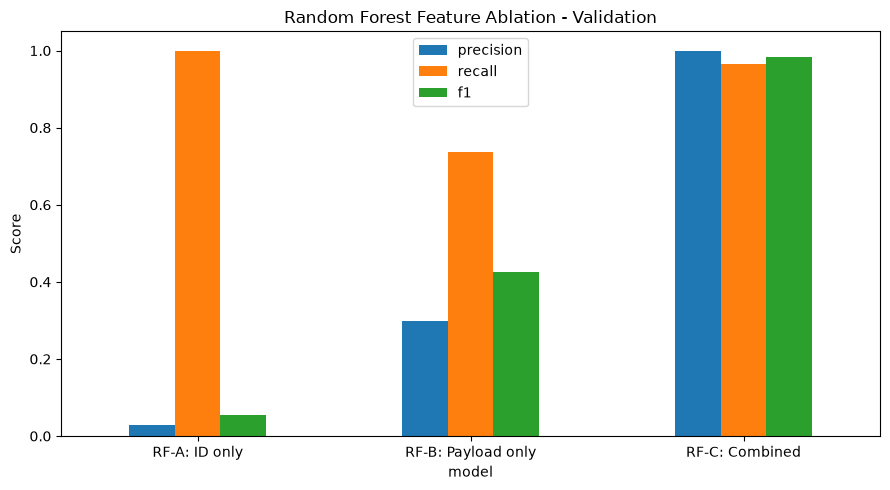

In [12]:

import matplotlib.pyplot as plt

ax = results_df.set_index("model")[
    ["precision", "recall", "f1"]
].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title(
    "Random Forest Feature Ablation - Validation"
)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()


In [13]:

# Examine how each feature set performs per capture

capture_results = []

for name, columns in feature_sets.items():

    model = fitted_models[name]
    predictions = model.predict(X_val[columns])

    analysis = pd.DataFrame({
        "source_file": df.loc[
            validation_mask, "source_file"
        ].to_numpy(),
        "actual": y_val.to_numpy(),
        "predicted": predictions
    })

    analysis["tp"] = (
        (analysis["actual"] == 1) &
        (analysis["predicted"] == 1)
    ).astype(int)

    analysis["fp"] = (
        (analysis["actual"] == 0) &
        (analysis["predicted"] == 1)
    ).astype(int)

    analysis["fn"] = (
        (analysis["actual"] == 1) &
        (analysis["predicted"] == 0)
    ).astype(int)

    summary = analysis.groupby("source_file").agg(
        frames=("actual", "size"),
        attacks=("actual", "sum"),
        detected=("tp", "sum"),
        false_alarms=("fp", "sum"),
        missed=("fn", "sum")
    )

    summary["recall"] = (
        summary["detected"] /
        summary["attacks"].replace(0, float("nan"))
    )

    summary["model"] = name

    capture_results.append(summary.reset_index())

capture_comparison = pd.concat(
    capture_results, ignore_index=True
)

display(
    capture_comparison[
        [
            "model",
            "source_file",
            "attacks",
            "detected",
            "missed",
            "false_alarms",
            "recall"
        ]
    ].round(4)
)


,model,source_file,attacks,detected,missed,false_alarms,recall
0,RF-A: ID only,train_01/DoS-1.csv,195,195,0,282,1.0
1,RF-A: ID only,train_01/rpm-2.csv,9,9,0,2610,1.0
2,RF-A: ID only,train_01/standstill-1.csv,61,61,0,6218,1.0
3,RF-B: Payload only,train_01/DoS-1.csv,195,195,0,13,1.0
4,RF-B: Payload only,train_01/rpm-2.csv,9,0,9,135,0.0
5,RF-B: Payload only,train_01/standstill-1.csv,61,0,61,311,0.0
6,RF-C: Combined,train_01/DoS-1.csv,195,195,0,0,1.0
7,RF-C: Combined,train_01/rpm-2.csv,9,0,9,0,0.0
8,RF-C: Combined,train_01/standstill-1.csv,61,61,0,0,1.0


## Two-way paired-capture validation

In [14]:

from sklearn.base import clone
from canids.experiment import score
import pandas as pd

# Identify capture number from filename
capture_number = df["source_file"].str.extract(
    r"-([12])\.csv$",
    expand=False
)

assert capture_number.notna().all(), (
    "Some training files do not follow the -1/-2 naming pattern."
)

fold_results = []

for held_out in ["1", "2"]:

    train_mask = capture_number != held_out
    val_mask = capture_number == held_out

    print(f"\n=== Validating on *-{held_out} captures ===")

    for name, columns in feature_sets.items():

        # Clone creates a new, unfitted model
        model = clone(fitted_models[name])

        model.fit(
            X.loc[train_mask, columns],
            y.loc[train_mask]
        )

        metrics = score(
            model,
            X.loc[val_mask, columns],
            y.loc[val_mask]
        )

        fold_results.append({
            "validation_group": f"*-{held_out}",
            "model": name,
            "attack_frames": metrics["positives"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"],
            "false_positive_rate": metrics["false_positive_rate"],
            "tp": metrics["tp"],
            "fp": metrics["fp"],
            "fn": metrics["fn"]
        })

fold_df = pd.DataFrame(fold_results)

display(fold_df.round(4))



=== Validating on *-1 captures ===

=== Validating on *-2 captures ===


,validation_group,model,attack_frames,precision,recall,f1,false_positive_rate,tp,fp,fn
0,*-1,RF-A: ID only,426,0.0200,0.7183,0.0388,0.1310,306,15026,120
1,*-1,RF-B: Payload only,426,0.1528,0.4577,0.2291,0.0094,195,1081,231
2,*-1,RF-C: Combined,426,0.7836,0.7394,0.7609,0.0008,315,87,111
3,*-2,RF-A: ID only,586,0.0072,0.0990,0.0134,0.0824,58,8011,528
4,*-2,RF-B: Payload only,586,0.3860,0.9249,0.5447,0.0089,542,862,44
5,*-2,RF-C: Combined,586,1.0000,0.0239,0.0467,0.0000,14,0,572


In [15]:

from sklearn.base import clone
import pandas as pd

# Identify capture groups
capture_group = df["source_file"].str.extract(
    r"-([12])\.csv$",
    expand=False
)

# Focus on the combined-feature Random Forest
model_name = "RF-C: Combined"
columns = feature_sets[model_name]

capture_reports = []

for held_out in ["1", "2"]:

    train_mask = capture_group != held_out
    val_mask = capture_group == held_out

    # Fresh model for every fold
    model = clone(fitted_models[model_name])

    model.fit(
        X.loc[train_mask, columns],
        y.loc[train_mask]
    )

    predictions = model.predict(
        X.loc[val_mask, columns]
    )

    analysis = df.loc[
        val_mask, ["source_file", "attack"]
    ].copy()

    analysis["prediction"] = predictions

    analysis["tp"] = (
        (analysis["attack"] == 1) &
        (analysis["prediction"] == 1)
    ).astype(int)

    analysis["fp"] = (
        (analysis["attack"] == 0) &
        (analysis["prediction"] == 1)
    ).astype(int)

    analysis["fn"] = (
        (analysis["attack"] == 1) &
        (analysis["prediction"] == 0)
    ).astype(int)

    report = analysis.groupby("source_file").agg(
        attacks=("attack", "sum"),
        detected=("tp", "sum"),
        missed=("fn", "sum"),
        false_alarms=("fp", "sum")
    )

    report["recall"] = (
        report["detected"] /
        report["attacks"].replace(0, float("nan"))
    )

    report["fold"] = f"Validate *-{held_out}"

    capture_reports.append(report.reset_index())

fold_capture_df = pd.concat(
    capture_reports,
    ignore_index=True
)

display(
    fold_capture_df[
        [
            "fold",
            "source_file",
            "attacks",
            "detected",
            "missed",
            "false_alarms",
            "recall"
        ]
    ].round(4)
)


,fold,source_file,attacks,detected,missed,false_alarms,recall
0,Validate *-1,train_01/DoS-1.csv,195,195,0,0,1.0
1,Validate *-1,train_01/accessory-1.csv,0,0,0,85,NaN
2,Validate *-1,train_01/attack-free-1.csv,0,0,0,0,NaN
3,Validate *-1,train_01/force-neutral-1.csv,120,120,0,2,1.0
4,Validate *-1,train_01/rpm-1.csv,50,0,50,0,0.0
5,Validate *-1,train_01/standstill-1.csv,61,0,61,0,0.0
6,Validate *-2,train_01/DoS-2.csv,528,0,528,0,0.0
7,Validate *-2,train_01/accessory-2.csv,0,0,0,0,NaN
8,Validate *-2,train_01/attack-free-2.csv,0,0,0,0,NaN
9,Validate *-2,train_01/force-neutral-2.csv,14,14,0,0,1.0
